# Native Particle Construction

ParticleData holds per-material masses, population weights, charge, density
and volume. Its explicit distribution type defines how to interpret weights.
This tutorial builds radius bins, speciated mass bins and a lognormal preset.
Activity and surface strategies remain separate process configuration.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import particula as par

## Initialize from radii with explicit units

Discrete concentrations are number densities. Binned data uses a unit
reference volume; per-particle masses follow the spherical volume formula.

In [2]:
input_radius_nm = np.array([100, 200, 300], dtype=np.float64)
input_concentration_cm3 = np.array([1e2, 1e3, 1e4], dtype=np.float64)
particle_data = par.particles.create_particle_data_from_radii(
    radii=input_radius_nm,
    radius_units="nm",
    concentration=input_concentration_cm3,
    concentration_units="1/cm^3",
    density=2.5,
    density_units="g/cm^3",
    distribution_type="discrete",
)
surface_strategy = (
    par.particles.SurfaceStrategyMassBuilder()
    .set_surface_tension(0.072, "N/m")
    .set_density(2.5, "g/cm^3")
    .build()
)
activity_strategy = par.particles.ActivityFactory().get_strategy("mass_ideal")
print("Per-particle mass [kg]:", particle_data.total_mass)
print("Radius [m]:", particle_data.radii)
print("Material mass density [kg/m^3]:", particle_data.species_mass_density)

Per-particle mass [kg]: [[1.04719755e-17 8.37758041e-17 2.82743339e-16]]
Radius [m]: [[1.e-07 2.e-07 3.e-07]]
Material mass density [kg/m^3]: [[2.91225639e-06]]


## Build speciated mass bins

The native builder replaces facade construction. Three material lanes each
have density 2500 kg/m^3. Use an explicit seed for reproducible illustrations.
Picograms are converted to kg explicitly (1 pg = 1e-15 kg). Activity and
surface strategy factories remain useful independently of data construction.

In [3]:
rng = np.random.default_rng(42)
mass_distribution_pg = rng.random((500, 3))
concentration_cm3 = rng.random(500) * 1e3
speciated_data = (
    par.particles.ParticleDataBuilder()
    .set_distribution_type("discrete")
    .set_masses(mass_distribution_pg * 1e-15)
    .set_density(np.full(3, 2500.0))
    .set_concentration(concentration_cm3, "1/cm^3")
    .set_charge(np.zeros(500))
    .set_volume(np.array([1.0]))
    .build()
)
print("Material mass density [kg/m^3]:", speciated_data.species_mass_density)
radius = speciated_data.radii[0]
masses = speciated_data.total_mass[0]
concentration = speciated_data.slot_concentration_density[0]

Material mass density [kg/m^3]: [[0.0001296  0.00012898 0.00013249]]


The mass histogram counts computational bins. The radius histogram weights
bins by their number density, so its vertical axis is a physical density.

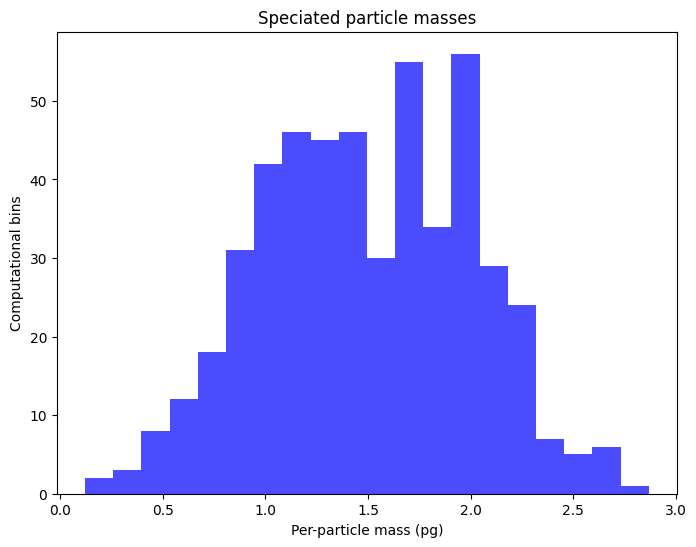

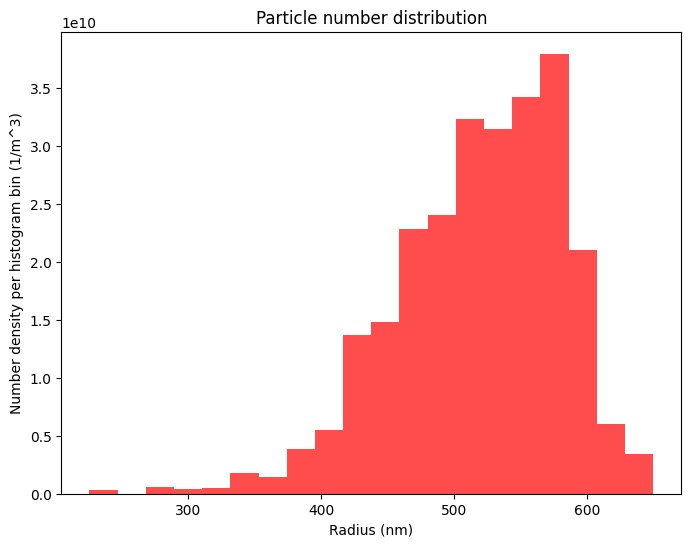

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(masses * 1e15, bins=20, color="blue", alpha=0.7)
ax.set_xlabel("Per-particle mass (pg)")
ax.set_ylabel("Computational bins")
ax.set_title("Speciated particle masses")
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(radius * 1e9, weights=concentration, bins=20, color="red", alpha=0.7)
ax.set_ylabel("Number density per histogram bin (1/m^3)")
ax.set_xlabel("Radius (nm)")
ax.set_title("Particle number distribution")
plt.show()

## Initialize a lognormal population

Preserve the two 100 nm and 2000 nm modes, each contributing 1e4 cm^-3.
The discrete preset normalizes the sampled bins to the specified number.

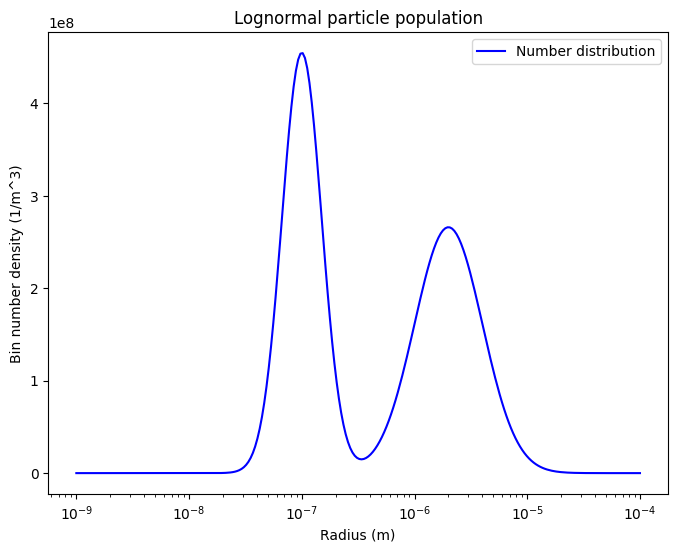

In [5]:
lognormal_data = par.particles.create_lognormal_binned_particle_data(
    distribution_type="discrete",
    mode=[100e-9, 2000e-9],
    geometric_standard_deviation=[1.5, 2.0],
    number_concentration=[1e10, 1e10],
)
fig, ax = plt.subplots(figsize=(8, 6))
ax.semilogx(
    lognormal_data.radii[0],
    lognormal_data.slot_concentration_density[0],
    label="Number distribution",
    color="blue",
)
ax.set_xlabel("Radius (m)")
ax.set_ylabel("Bin number density (1/m^3)")
ax.set_title("Lognormal particle population")
ax.legend()
plt.show()

Native constructors and builders retain useful initialization choices.
Raw fields remain mutable; derived properties return computed values. Use
`copy()` for independent storage and validate after directly changing arrays.